In [1]:
# =========================================================
# Credit Card Fraud Detection - Exploratory Data Analysis
# =========================================================

# 1. Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot settings
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

# 2. Load dataset
df = pd.read_csv('/Users/margarita/CreditCardEda/data/creditcard.csv')

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [2]:
# 3. Basic information
print("\n--- Dataset Info ---")
df.info()

print("\n--- Missing values ---")
print(df.isnull().sum().sum())


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  f


--- Class Distribution ---
Class
0    284315
1       492
Name: count, dtype: int64

Percentage:
Class
0   99.8273
1    0.1727
Name: proportion, dtype: float64


/var/folders/6d/96xf9x4j2zv5n3ckwthv_k680000gn/T/ipykernel_51622/36563292.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df, ax=ax[0], palette=['#2ecc71', '#e74c3c'])


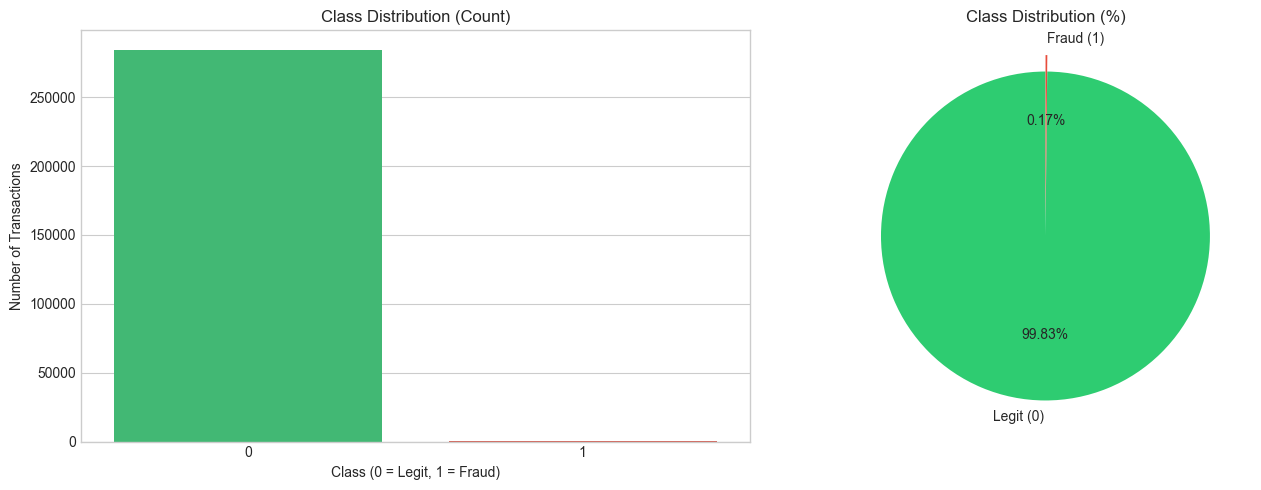

In [3]:
# 4. Target variable distribution (Class)
print("\n--- Class Distribution ---")
class_counts = df['Class'].value_counts()
class_percent = df['Class'].value_counts(normalize=True) * 100

print(class_counts)
print("\nPercentage:")
print(class_percent)

# Visualization
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
sns.countplot(x='Class', data=df, ax=ax[0], palette=['#2ecc71', '#e74c3c'])
ax[0].set_title('Class Distribution (Count)')
ax[0].set_xlabel('Class (0 = Legit, 1 = Fraud)')
ax[0].set_ylabel('Number of Transactions')

# Pie chart
ax[1].pie(class_counts, labels=['Legit (0)', 'Fraud (1)'],
          autopct='%1.2f%%', colors=['#2ecc71', '#e74c3c'],
          startangle=90, explode=(0, 0.1))
ax[1].set_title('Class Distribution (%)')

plt.tight_layout()
plt.show()

In [4]:
# 5. Descriptive statistics by class
print("\n--- Amount statistics by Class ---")
print(df.groupby('Class')['Amount'].describe())


--- Amount statistics by Class ---
            count     mean      std    min    25%     50%      75%        max
Class                                                                        
0     284315.0000  88.2910 250.1051 0.0000 5.6500 22.0000  77.0500 25691.1600
1        492.0000 122.2113 256.6833 0.0000 1.0000  9.2500 105.8900  2125.8700


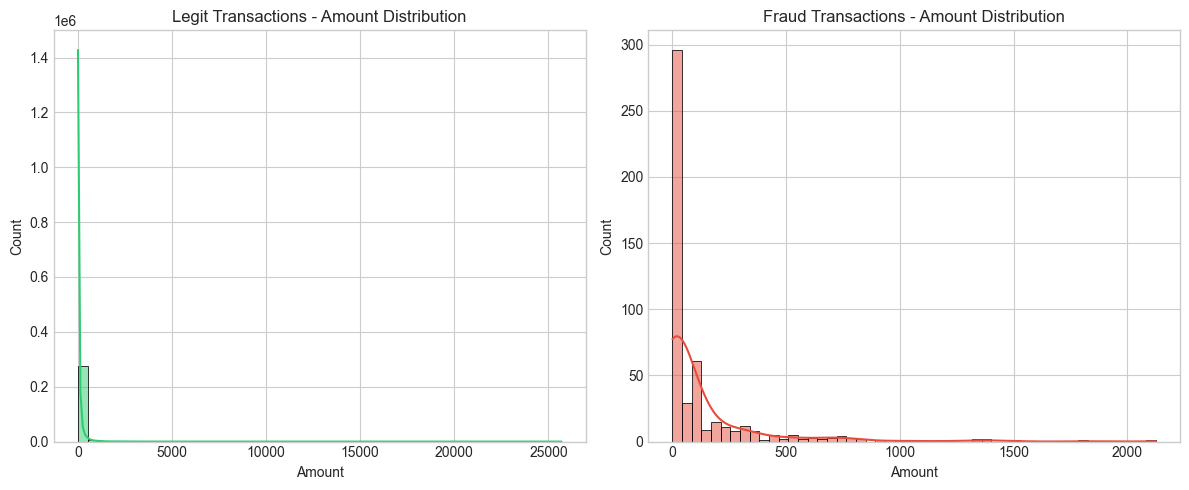

In [5]:
# 6. Distribution of transaction amount
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df[df['Class'] == 0]['Amount'], bins=50, color='#2ecc71', kde=True)
plt.title('Legit Transactions - Amount Distribution')
plt.xlabel('Amount')

plt.subplot(1, 2, 2)
sns.histplot(df[df['Class'] == 1]['Amount'], bins=50, color='#e74c3c', kde=True)
plt.title('Fraud Transactions - Amount Distribution')
plt.xlabel('Amount')

plt.tight_layout()
plt.show()

In [6]:
# 7. Correlation with target (quick look)
corr = df.corr(numeric_only=True)['Class'].sort_values(ascending=False)
print("\n--- Top correlations with Class ---")
print(corr.head(10))
print("\n--- Lowest correlations with Class ---")
print(corr.tail(10))


--- Top correlations with Class ---
Class   1.0000
V11     0.1549
V4      0.1334
V2      0.0913
V21     0.0404
V19     0.0348
V20     0.0201
V8      0.0199
V27     0.0176
V28     0.0095
Name: Class, dtype: float64

--- Lowest correlations with Class ---
V9    -0.0977
V1    -0.1013
V18   -0.1115
V7    -0.1873
V3    -0.1930
V16   -0.1965
V10   -0.2169
V12   -0.2606
V14   -0.3025
V17   -0.3265
Name: Class, dtype: float64


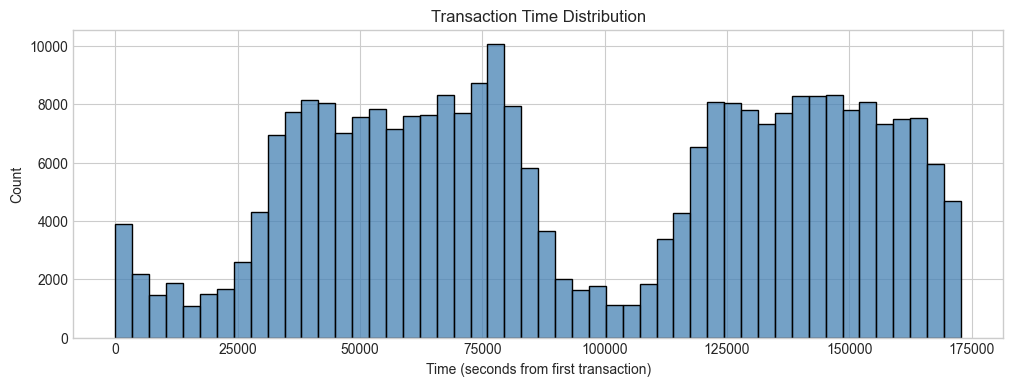

In [7]:
# 8. Time feature quick look
plt.figure(figsize=(12, 4))
sns.histplot(df['Time'], bins=50, color='steelblue')
plt.title('Transaction Time Distribution')
plt.xlabel('Time (seconds from first transaction)')
plt.show()

In [8]:

# ---------------------------------------------------------
# 1. Basic time-based feature
# ---------------------------------------------------------
# Time column shows seconds elapsed from the first transaction
# We create a simple feature: hour of the day (optional)

df['Hour'] = (df['Time'] // 3600) % 24

# ---------------------------------------------------------
# 2. Transaction amount features
# ---------------------------------------------------------

# Log of amount (helps with skewed distribution)
df['Amount_log'] = np.log1p(df['Amount'])

# ---------------------------------------------------------
# 3. User-level features (important for fraud)
# ---------------------------------------------------------
# Since this dataset does not have real user_id,
# we will simulate user behavior using rolling statistics.
# In real projects you will group by real user_id / card_id.

# For demonstration we create features based on the whole dataset order.
# In real life replace this with groupby('user_id').

df = df.sort_values('Time').reset_index(drop=True)

# Time difference from previous transaction (in seconds)
df['Time_diff'] = df['Time'].diff()

# Rolling mean of amount (last 5 transactions)
df['Amount_roll_mean_5'] = df['Amount'].rolling(window=5, min_periods=1).mean()

# How much current amount differs from recent average
df['Amount_diff_from_roll_mean'] = df['Amount'] - df['Amount_roll_mean_5']

# Absolute deviation
df['Amount_abs_diff'] = df['Amount_diff_from_roll_mean'].abs()

# ---------------------------------------------------------
# 4. Simple statistical features
# ---------------------------------------------------------

df['Amount_zscore'] = (df['Amount'] - df['Amount'].mean()) / df['Amount'].std()

# ---------------------------------------------------------
# 5. Check new features
# ---------------------------------------------------------

print("New features created:")
print(df[['Time', 'Amount', 'Time_diff', 'Amount_roll_mean_5', 
          'Amount_diff_from_roll_mean', 'Amount_zscore']].head(10))

print("\nDataset shape after feature engineering:", df.shape)


New features created:
    Time   Amount  Time_diff  Amount_roll_mean_5  Amount_diff_from_roll_mean  \
0 0.0000 149.6200        NaN            149.6200                      0.0000   
1 0.0000   2.6900     0.0000             76.1550                    -73.4650   
2 1.0000 378.6600     1.0000            176.9900                    201.6700   
3 1.0000 123.5000     0.0000            163.6175                    -40.1175   
4 2.0000  69.9900     1.0000            144.8920                    -74.9020   
5 2.0000   3.6700     0.0000            115.7020                   -112.0320   
6 4.0000   4.9900     2.0000            116.1620                   -111.1720   
7 7.0000  40.8000     3.0000             48.5900                     -7.7900   
8 7.0000  93.2000     0.0000             42.5300                     50.6700   
9 9.0000   3.6800     2.0000             29.2680                    -25.5880   

   Amount_zscore  
0         0.2450  
1        -0.3425  
2         1.1607  
3         0.1405  
4 

Top positive correlations with Class:
Class       1.0000
V11         0.1549
V4          0.1334
V2          0.0913
V21         0.0404
V19         0.0348
V20         0.0201
V8          0.0199
Time_diff   0.0190
V27         0.0176
Name: Class, dtype: float64

Top negative correlations with Class:
V9    -0.0977
V1    -0.1013
V18   -0.1115
V7    -0.1873
V3    -0.1930
V16   -0.1965
V10   -0.2169
V12   -0.2606
V14   -0.3025
V17   -0.3265
Name: Class, dtype: float64


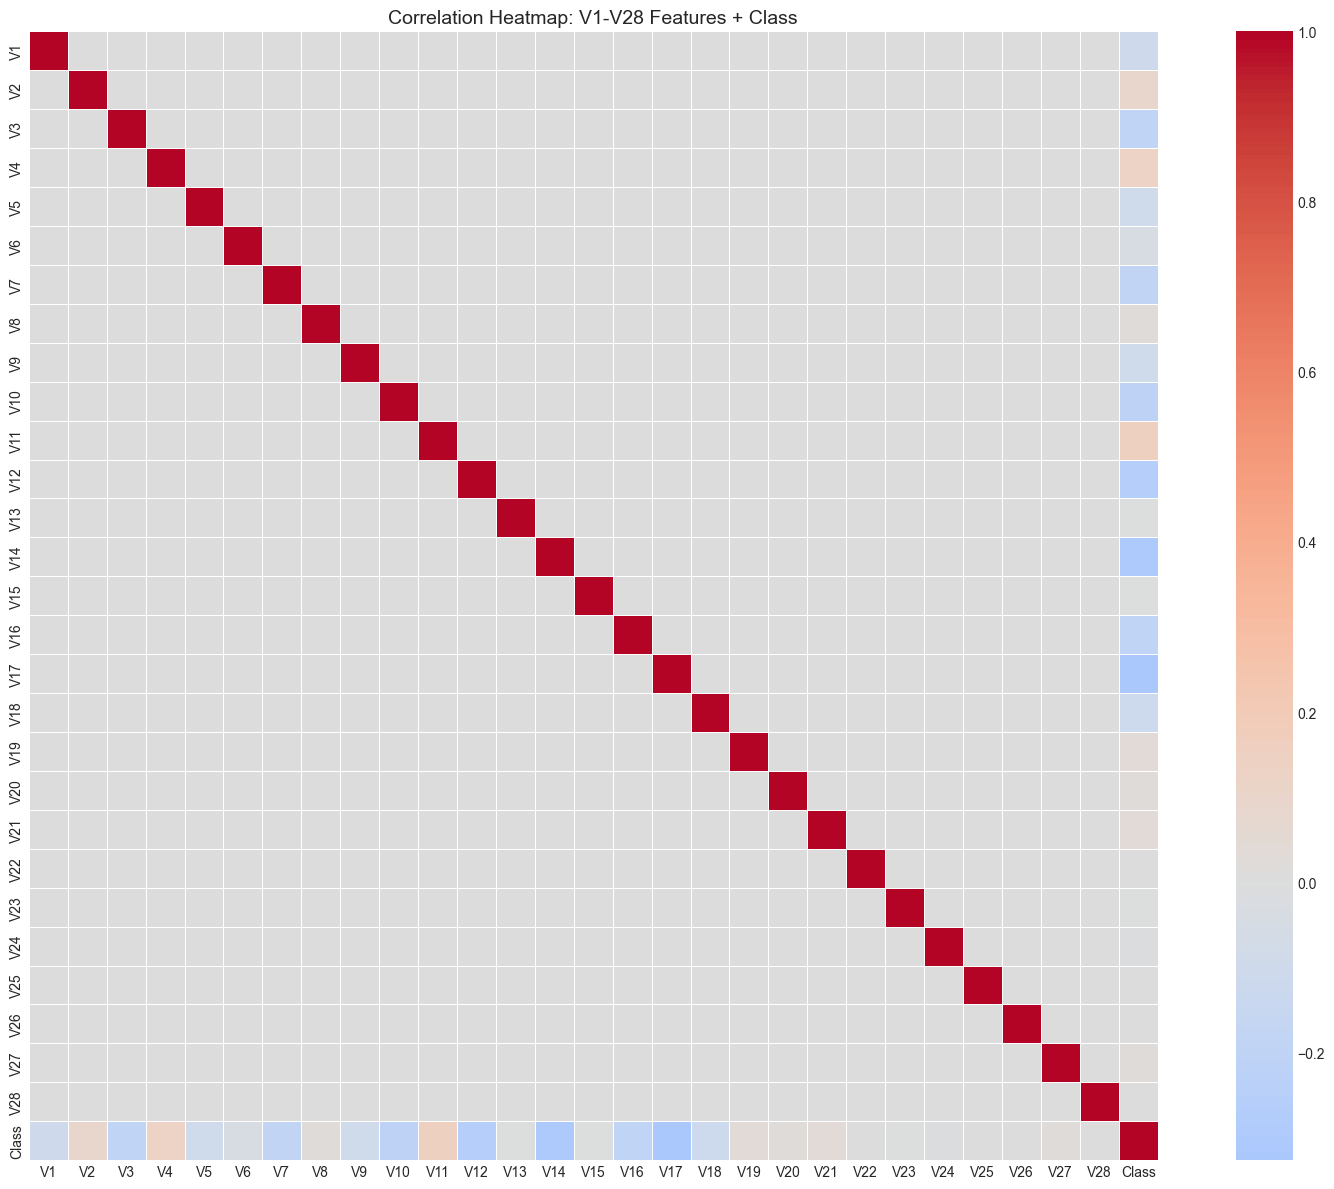

/var/folders/6d/96xf9x4j2zv5n3ckwthv_k680000gn/T/ipykernel_51622/2751980515.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


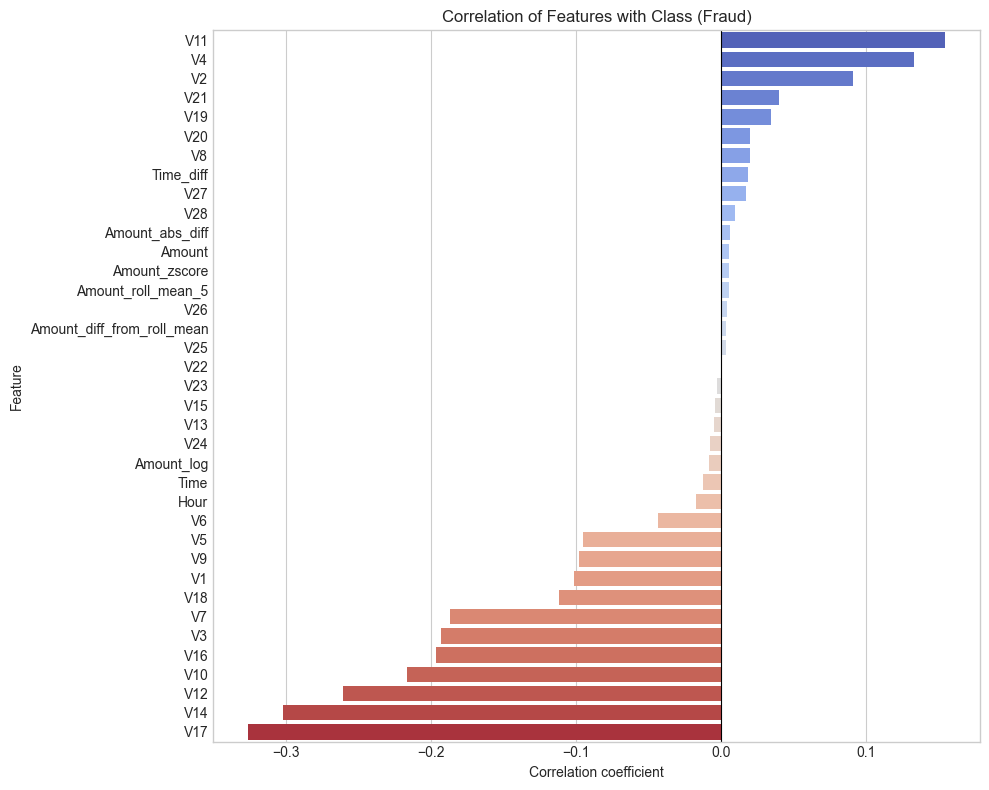

Features with |correlation| > 0.1:
V11    0.1549
V4     0.1334
V1    -0.1013
V18   -0.1115
V7    -0.1873
V3    -0.1930
V16   -0.1965
V10   -0.2169
V12   -0.2606
V14   -0.3025
V17   -0.3265
Name: Class, dtype: float64


In [9]:
# ---------------------------------------------------------
# 1. Correlation with target (Class)
# ---------------------------------------------------------
# Calculate correlation of all features with Class
corr_with_class = df.corr(numeric_only=True)['Class'].sort_values(ascending=False)

print("Top positive correlations with Class:")
print(corr_with_class.head(10))

print("\nTop negative correlations with Class:")
print(corr_with_class.tail(10))
# ---------------------------------------------------------
# 2. Heatmap of V1-V28 + Class
# ---------------------------------------------------------

# Select only V-features + Class
v_features = [col for col in df.columns if col.startswith('V')] + ['Class']
corr_matrix = df[v_features].corr()

# Plot heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    annot=False,          # set True if you want numbers (can be slow)
    fmt=".2f",
    linewidths=0.5,
    square=True
)
plt.title('Correlation Heatmap: V1-V28 Features + Class', fontsize=14)
plt.tight_layout()
plt.show()
# ---------------------------------------------------------
# 3. Focused heatmap: only correlations with Class
# ---------------------------------------------------------

# Create a nice bar view of correlations with Class
plt.figure(figsize=(10, 8))
corr_class = corr_with_class.drop('Class')  # remove self-correlation

sns.barplot(
    x=corr_class.values,
    y=corr_class.index,
    palette='coolwarm'
)
plt.title('Correlation of Features with Class (Fraud)')
plt.xlabel('Correlation coefficient')
plt.ylabel('Feature')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()
# ---------------------------------------------------------
# 4. Strongest features
# ---------------------------------------------------------

strong_features = corr_with_class[abs(corr_with_class) > 0.1].drop('Class')
print("Features with |correlation| > 0.1:")
print(strong_features)

Legit transactions: 284315
Fraud transactions: 492


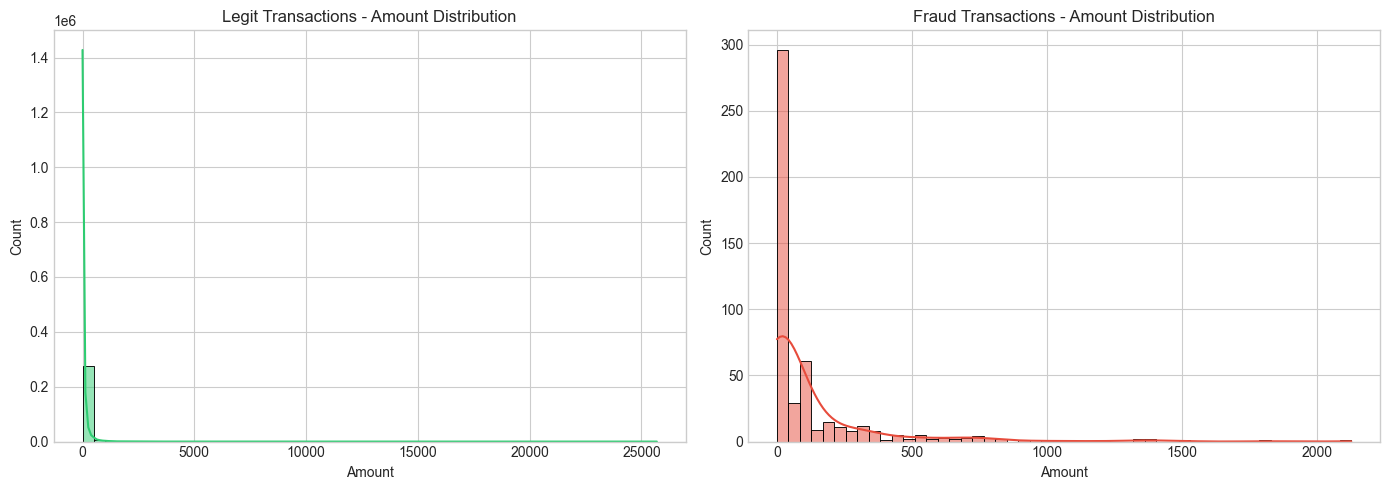

In [11]:
legit = df[df['Class'] == 0]
fraud = df[df['Class'] == 1]

print("Legit transactions:", legit.shape[0])
print("Fraud transactions:", fraud.shape[0])
# ---------------------------------------------------------
# 1. Histogram of Amount (Legit vs Fraud)
# ---------------------------------------------------------

plt.figure(figsize=(14, 5))

# Legit
plt.subplot(1, 2, 1)
sns.histplot(legit['Amount'], bins=50, color='#2ecc71', kde=True)
plt.title('Legit Transactions - Amount Distribution')
plt.xlabel('Amount')
plt.ylabel('Count')

# Fraud
plt.subplot(1, 2, 2)
sns.histplot(fraud['Amount'], bins=50, color='#e74c3c', kde=True)
plt.title('Fraud Transactions - Amount Distribution')
plt.xlabel('Amount')
plt.ylabel('Count')

plt.tight_layout()
plt.show()
# ---------------------------------------------------------


/var/folders/6d/96xf9x4j2zv5n3ckwthv_k680000gn/T/ipykernel_51622/1678373397.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


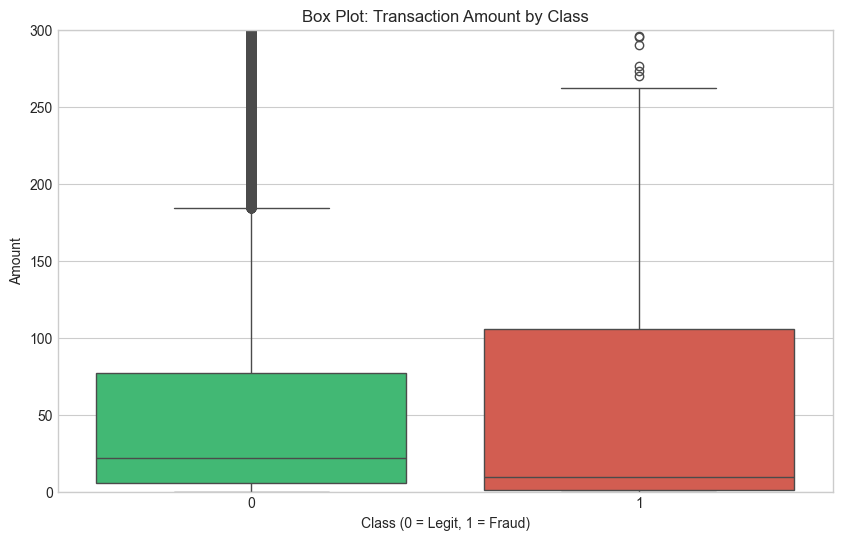

In [12]:
# 2. Box Plot (самый важный график дня)
# ---------------------------------------------------------

plt.figure(figsize=(10, 6))
sns.boxplot(
    x='Class',
    y='Amount',
    data=df,
    palette=['#2ecc71', '#e74c3c']
)
plt.title('Box Plot: Transaction Amount by Class')
plt.xlabel('Class (0 = Legit, 1 = Fraud)')
plt.ylabel('Amount')
plt.ylim(0, 300)  # zoom to see the main range better
plt.show()
#

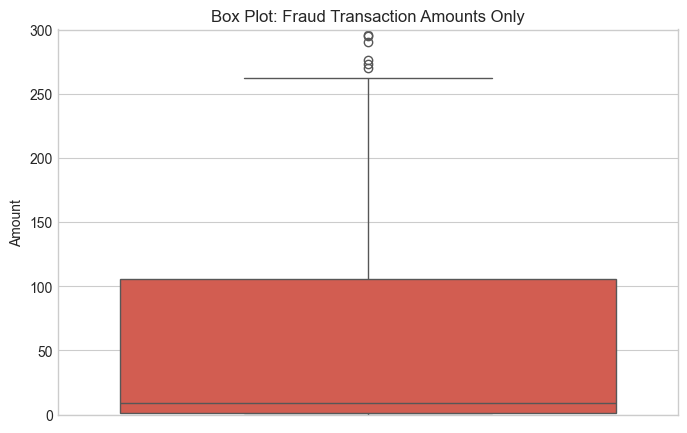

In [14]:

# 3. Zoomed Box Plot only for Fraud (better view)
# ---------------------------------------------------------

plt.figure(figsize=(8, 5))
sns.boxplot(
    y=fraud['Amount'],
    color='#e74c3c'
)
plt.title('Box Plot: Fraud Transaction Amounts Only')
plt.ylabel('Amount')
plt.ylim(0, 300)
plt.show()
# ---------------------------------------------------------


In [ ]:

# 4. Key statistics
# ---------------------------------------------------------

print("=== Amount Statistics ===")
print("\nLegit transactions:")
print(legit['Amount'].describe())

print("\nFraud transactions:")
print(fraud['Amount'].describe())

=== Amount Statistics ===

Legit transactions:
count   284315.0000
mean        88.2910
std        250.1051
min          0.0000
25%          5.6500
50%         22.0000
75%         77.0500
max      25691.1600
Name: Amount, dtype: float64

Fraud transactions:
count    492.0000
mean     122.2113
std      256.6833
min        0.0000
25%        1.0000
50%        9.2500
75%      105.8900
max     2125.8700
Name: Amount, dtype: float64
